# Week 10 – CNN Laboratory Activity: Step-by-Step Guide
**IT414 – IT Elective 3 (DSS Technologies)** · 1st Sem, SY2026-2027

**Group members:** Gracielle Mieh C. Layam
**Section:** BSIT 4R10

## Step 0 – Setup
Import libraries and fix the random seeds so the results are reproducible.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
from tensorflow.keras import layers, models

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.22.0-rc0


## Step 1 – Task 1: Problem framing & data plan
**Requirements:** task statement (dataset, input size, number of classes), splits with exact counts, preprocessing (normalization and resizing), class names and counts with any imbalance noted, and source/license.

### 1.1 Task statement

In [20]:
(x_full, y_full), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()

y_full = y_full.flatten()
y_test = y_test.flatten()

class_names = ["airplane", "automobile", "bird", "cat", "deer",
               "dog", "frog", "horse", "ship", "truck"]

print("Task: 10-class image classification with a CNN")
print("Dataset: CIFAR-10")
print("Input size:", x_full.shape[1:])  
print("Number of classes:", len(class_names))
print("Original training images:", len(x_full))
print("Official test images:", len(x_test))
print("Total images:", len(x_full) + len(x_test))

Task: 10-class image classification with a CNN
Dataset: CIFAR-10
Input size: (32, 32, 3)
Number of classes: 10
Original training images: 50000
Official test images: 10000
Total images: 60000


**📸 Screenshot** the cell above (Task 1 – task statement).

### 1.2 Fixed train / validation / test split (exact counts)
The validation set is carved out of the **original training set only**. The official test set is never touched until final evaluation, so there is **no test leakage**.

In [5]:
indices = np.arange(len(x_full))

train_idx, val_idx = train_test_split(
    indices,
    test_size=10000,
    random_state=SEED,
    stratify=y_full
)

x_train, y_train = x_full[train_idx], y_full[train_idx]
x_val,   y_val   = x_full[val_idx],   y_full[val_idx]

print("Training images:  ", len(x_train))
print("Validation images:", len(x_val))
print("Testing images:   ", len(x_test))
print("Random seed:      ", SEED)
print("Split method: stratified; test set = official CIFAR-10 test set")

Training images:   40000
Validation images: 10000
Testing images:    10000
Random seed:       42
Split method: stratified; test set = official CIFAR-10 test set


**📸 Screenshot** the cell above (Task 1 – splits).

### 1.3 Class names, counts, and imbalance check

In [6]:
class_distribution = pd.DataFrame({
    "Class": class_names,
    "Train": np.bincount(y_train, minlength=10),
    "Validation": np.bincount(y_val, minlength=10),
    "Test": np.bincount(y_test, minlength=10),
})
class_distribution["Total"] = class_distribution[["Train", "Validation", "Test"]].sum(axis=1)
display(class_distribution)

total_counts = class_distribution["Total"]
ratio = total_counts.max() / total_counts.min()
print(f"Largest/smallest class ratio: {ratio:.2f}")
print("Class imbalance:", "NONE (perfectly balanced)" if ratio == 1 else f"present (ratio {ratio:.2f})")

,Class,Train,Validation,Test,Total
0,airplane,4000,1000,1000,6000
1,automobile,4000,1000,1000,6000
2,bird,4000,1000,1000,6000
3,cat,4000,1000,1000,6000
4,deer,4000,1000,1000,6000
5,dog,4000,1000,1000,6000
6,frog,4000,1000,1000,6000
7,horse,4000,1000,1000,6000
8,ship,4000,1000,1000,6000
9,truck,4000,1000,1000,6000


Largest/smallest class ratio: 1.00
Class imbalance: NONE (perfectly balanced)


### 1.4 Preprocessing (normalization and resizing)
State the resizing **explicitly**, even if you do not resize. CIFAR-10 images are already 32×32, so **no resizing** is applied.

Resizing: NONE - images are kept at 32x32x3
Normalization: pixel values scaled from [0, 255] to [0.0, 1.0] (divide by 255)
Training shape:   (40000, 32, 32, 3)
Validation shape: (10000, 32, 32, 3)
Testing shape:    (10000, 32, 32, 3)
Pixel range: 0.0 to 1.0


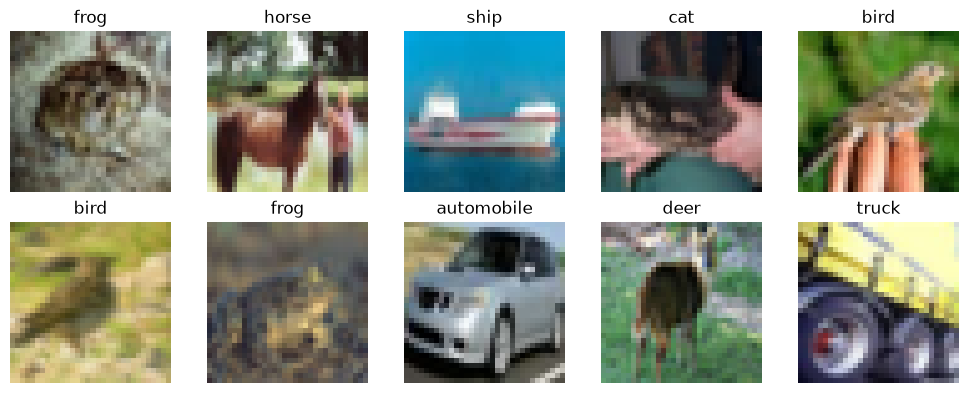

In [7]:
x_train = x_train.astype("float32") / 255.0
x_val   = x_val.astype("float32") / 255.0
x_test  = x_test.astype("float32") / 255.0

print("Resizing: NONE - images are kept at 32x32x3")
print("Normalization: pixel values scaled from [0, 255] to [0.0, 1.0] (divide by 255)")
print("Training shape:  ", x_train.shape)
print("Validation shape:", x_val.shape)
print("Testing shape:   ", x_test.shape)
print("Pixel range:", x_train.min(), "to", x_train.max())

plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[y_train[i]])
    plt.axis("off")
plt.tight_layout()
plt.show()

## Step 2 – Helper functions
Reusable functions for plotting training curves, so every model is reported the same way.

In [8]:
def plot_history(history, title):
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(history.history["accuracy"], label="Training")
    plt.plot(history.history["val_accuracy"], label="Validation")
    plt.title(f"{title} Accuracy")
    plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history.history["loss"], label="Training")
    plt.plot(history.history["val_loss"], label="Validation")
    plt.title(f"{title} Loss")
    plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend()

    plt.tight_layout()
    plt.show()

## Step 3 – Training plan (used by both models)
Declare the plan once so both models are compared fairly:

| Item | Value |
|---|---|
| Optimizer | Adam, learning rate 0.001 |
| Loss | sparse categorical cross-entropy |
| Batch size | 64 |
| Max epochs | 20 (≤ 20 as required) |
| Early stopping | monitor `val_accuracy`, mode `max`, restore best weights |

## Step 4 – Task 2: Model 1, user-defined baseline CNN
**Requirements:** 2–3 Conv→Activation→Pool blocks, small capacity, Dense/Softmax head.

### 4.1 Design

In [9]:
baseline_model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),

    # Convolution block 1
    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Convolution block 2
    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Classification head
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax"),
], name="baseline_cnn")

baseline_model.summary()

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       524,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 545,098 (2.08 MB)

 Trainable params: 545,098 (2.08 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
baseline_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_accuracy",
    mode="max",
    patience=3,
    restore_best_weights=True
)

baseline_history = baseline_model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=20,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 18s 26ms/step - accuracy: 0.4649 - loss: 1.4931 - val_accuracy: 0.5527 - val_loss: 1.2739
Epoch 2/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 15s 24ms/step - accuracy: 0.6050 - loss: 1.1181 - val_accuracy: 0.6167 - val_loss: 1.0867
Epoch 3/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 15s 23ms/step - accuracy: 0.6655 - loss: 0.9606 - val_accuracy: 0.6564 - val_loss: 0.9870
Epoch 4/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 15s 23ms/step - accuracy: 0.7036 - loss: 0.8569 - val_accuracy: 0.6763 - val_loss: 0.9423
Epoch 5/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 15s 23ms/step - accuracy: 0.7339 - loss: 0.7724 - val_accuracy: 0.6771 - val_loss: 0.9339
Epoch 6/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 15s 23ms/step - accuracy: 0.7596 - loss: 0.6987 - val_accuracy: 0.6787 - val_loss: 0.9605
Epoch 7/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 16s 25ms/step - accuracy: 0.7827 - loss: 0.6337 - val_accuracy: 0.6820 - val_loss: 0.9837
Epoch 8/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 19s 30ms/step - accuracy: 0.8029 - loss: 0.5746 - 

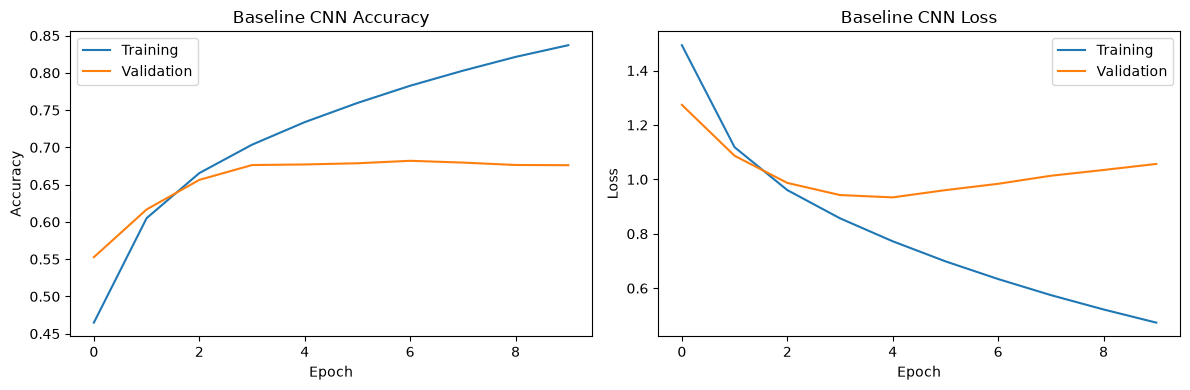

In [11]:
plot_history(baseline_history, "Baseline CNN")

## Step 5 – Task 3: Model 2, stronger CNN (deeper + BatchNorm + Dropout)
**Requirements:** stacked Conv + BatchNorm + ReLU blocks, plus Dropout.

### Why a "stronger" model can still lose
A deeper model with BatchNorm and Dropout is *expected* to beat a plain 2-block CNN on CIFAR-10, but it does not always. If you keep only light regularization and stop training early, it can overfit quickly or stop before it has learned enough. The version below adds three things that usually fix this, and you must **declare them in the report**:
1. **Data augmentation** (random horizontal flip and small random shifts, applied to training data only)
2. **More patience** in early stopping (5 instead of 3)
3. **Learning-rate reduction** when validation accuracy stalls

### 5.1 Design

In [21]:
augment = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomTranslation(0.1, 0.1),
], name="augmentation")


def conv_bn_relu(filters):
    return [
        layers.Conv2D(filters, 3, padding="same", use_bias=False),
        layers.BatchNormalization(),
        layers.Activation("relu"),
    ]


stronger_model = models.Sequential(
    [layers.Input(shape=(32, 32, 3)), augment]

    # Block 1
    + conv_bn_relu(32) + conv_bn_relu(32)
    + [layers.MaxPooling2D(), layers.Dropout(0.2)]

    # Block 2
    + conv_bn_relu(64) + conv_bn_relu(64)
    + [layers.MaxPooling2D(), layers.Dropout(0.3)]

    # Block 3
    + conv_bn_relu(128) + conv_bn_relu(128)
    + [layers.MaxPooling2D(), layers.Dropout(0.4)]

    # Classification head
    + [
        layers.GlobalAveragePooling2D(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.5),
        layers.Dense(10, activation="softmax"),
    ],
    name="stronger_cnn"
)

stronger_model.summary()

Model: "stronger_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augmentation (Sequential)       │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 32, 32, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 32, 32, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 16, 16, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_8 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 16, 16, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_9 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 8, 8, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_10 (Activation)      │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 8, 8, 128)      │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 306,154 (1.17 MB)

 Trainable params: 305,258 (1.16 MB)

 Non-trainable params: 896 (3.50 KB)

In [13]:
stronger_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

stronger_early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_accuracy",
    mode="max",
    patience=5,
    restore_best_weights=True
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_accuracy",
    mode="max",
    factor=0.5,
    patience=2,
    min_lr=1e-5,
    verbose=1
)

stronger_history = stronger_model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=20,
    batch_size=64,
    callbacks=[stronger_early_stop, reduce_lr],
    verbose=1
)

Epoch 1/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 90s 136ms/step - accuracy: 0.3882 - loss: 1.6586 - val_accuracy: 0.4340 - val_loss: 1.5597 - learning_rate: 0.0010
Epoch 2/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 82s 131ms/step - accuracy: 0.5342 - loss: 1.2960 - val_accuracy: 0.5592 - val_loss: 1.2351 - learning_rate: 0.0010
Epoch 3/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 83s 132ms/step - accuracy: 0.5973 - loss: 1.1374 - val_accuracy: 0.6034 - val_loss: 1.1207 - learning_rate: 0.0010
Epoch 4/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 82s 131ms/step - accuracy: 0.6327 - loss: 1.0417 - val_accuracy: 0.6252 - val_loss: 1.0754 - learning_rate: 0.0010
Epoch 5/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 83s 132ms/step - accuracy: 0.6592 - loss: 0.9731 - val_accuracy: 0.5759 - val_loss: 1.3819 - learning_rate: 0.0010
Epoch 6/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 82s 132ms/step - accuracy: 0.6820 - loss: 0.9152 - val_accuracy: 0.6671 - val_loss: 0.9737 - learning_rate: 0.0010
Epoch 7/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 78s 124ms/step - accuracy: 0.6

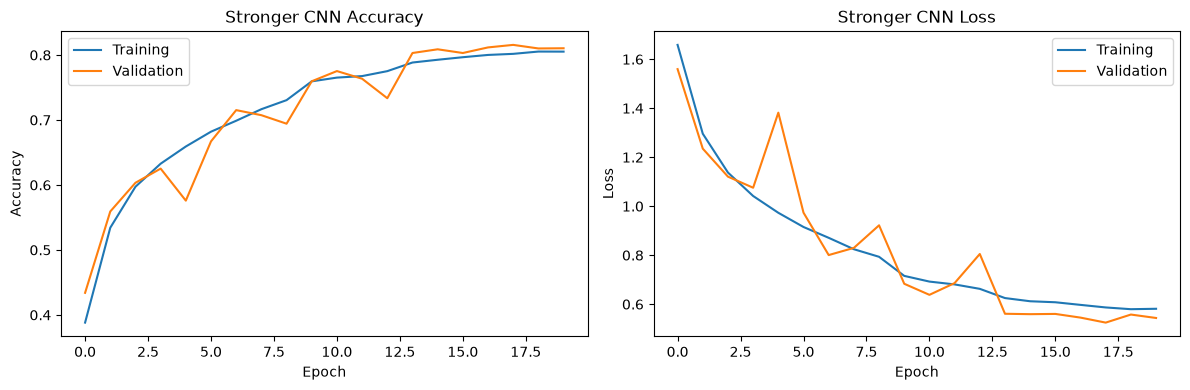

In [14]:
plot_history(stronger_history, "Stronger CNN")

## Step 6 – Task 4: Validation & test evaluation (both models)
**Requirement:** record the **best validation accuracy (with its epoch)** and the **final test accuracy**.

The test set is evaluated **once per model, at the end**. Because `restore_best_weights=True`, the model being tested is the best-validation-epoch model.

In [15]:
def get_best_validation(history):
    val_acc = history.history["val_accuracy"]
    best_index = int(np.argmax(val_acc))
    return val_acc[best_index] * 100, best_index + 1   # epochs are 1-indexed


baseline_val, baseline_epoch = get_best_validation(baseline_history)
stronger_val, stronger_epoch = get_best_validation(stronger_history)

baseline_test_loss, baseline_test_acc = baseline_model.evaluate(x_test, y_test, verbose=0)
stronger_test_loss, stronger_test_acc = stronger_model.evaluate(x_test, y_test, verbose=0)

print("BASELINE CNN")
print(f"Best validation accuracy: {baseline_val:.2f}%")
print(f"Best epoch: {baseline_epoch}")
print(f"Test accuracy: {baseline_test_acc * 100:.2f}%")

print("\nSTRONGER CNN")
print(f"Best validation accuracy: {stronger_val:.2f}%")
print(f"Best epoch: {stronger_epoch}")
print(f"Test accuracy: {stronger_test_acc * 100:.2f}%")

BASELINE CNN
Best validation accuracy: 68.20%
Best epoch: 7
Test accuracy: 68.67%

STRONGER CNN
Best validation accuracy: 81.56%
Best epoch: 18
Test accuracy: 81.57%


In [16]:
results = pd.DataFrame({
    "Model": ["User-Defined Baseline", "Stronger CNN"],
    "Best Val Acc (%)": [round(baseline_val, 2), round(stronger_val, 2)],
    "Epoch": [baseline_epoch, stronger_epoch],
    "Test Acc (%)": [round(baseline_test_acc * 100, 2), round(stronger_test_acc * 100, 2)],
    "Notes": [
        "2 conv blocks; no BatchNorm or Dropout",
        "3 conv blocks (6 conv layers); BatchNorm + Dropout; augmentation; LR reduction",
    ],
    "Parameters": [baseline_model.count_params(), stronger_model.count_params()],
})
display(results)

# Which model is best? Decide by VALIDATION accuracy (not test).
best_name = results.loc[results["Best Val Acc (%)"].idxmax(), "Model"]
print("Best model (by validation accuracy):", best_name)

,Model,Best Val Acc (%),Epoch,Test Acc (%),Notes,Parameters
0,User-Defined Baseline,68.20,7,68.67,2 conv blocks; no BatchNorm or Dropout,545098
1,Stronger CNN,81.56,18,81.57,3 conv blocks (6 conv layers); BatchNorm + Dro...,306154


Best model (by validation accuracy): Stronger CNN


## Step 7 – Confusion matrix for the **best** model
The activity asks for the confusion matrix of **your best model**. Use the model the cell above names as best. (Plotting both is a nice bonus for your analysis.)

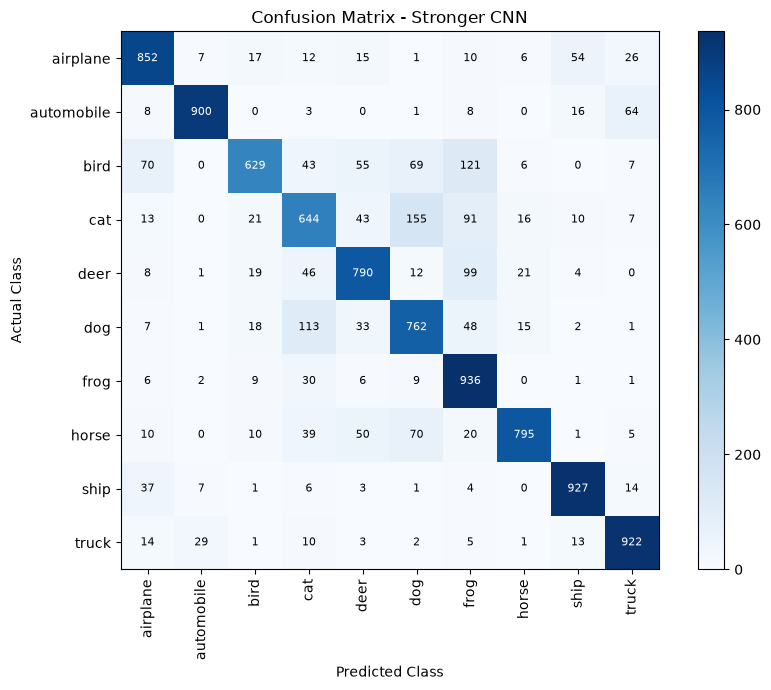

Top 5 confusions (actual -> predicted):
  cat -> dog: 155 (15.5% of all actual cat)
  bird -> frog: 121 (12.1% of all actual bird)
  dog -> cat: 113 (11.3% of all actual dog)
  deer -> frog: 99 (9.9% of all actual deer)
  cat -> frog: 91 (9.1% of all actual cat)


,Class,Correct,Accuracy
0,frog,936,93.6
1,ship,927,92.7
2,truck,922,92.2
3,automobile,900,90.0
4,airplane,852,85.2
5,horse,795,79.5
6,deer,790,79.0
7,dog,762,76.2
8,cat,644,64.4
9,bird,629,62.9


In [17]:
def get_predictions(model):
    probs = model.predict(x_test, verbose=0)
    return np.argmax(probs, axis=1)


def plot_cm(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(9, 7))
    im = ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(10)); ax.set_yticks(range(10))
    ax.set_xticklabels(class_names, rotation=90)
    ax.set_yticklabels(class_names)
    ax.set_xlabel("Predicted Class"); ax.set_ylabel("Actual Class")
    ax.set_title(title)
    thresh = cm.max() / 2
    for i in range(10):
        for j in range(10):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > thresh else "black", fontsize=8)
    fig.colorbar(im)
    plt.tight_layout()
    plt.show()
    return cm


def top_confusions(cm, k=5):
    off = cm.copy()
    np.fill_diagonal(off, 0)
    flat_order = np.argsort(off.ravel())[::-1][:k]
    print(f"Top {k} confusions (actual -> predicted):")
    for flat in flat_order:
        i, j = np.unravel_index(flat, off.shape)
        print(f"  {class_names[i]} -> {class_names[j]}: {off[i, j]} "
              f"({off[i, j] / cm[i].sum():.1%} of all actual {class_names[i]})")


def per_class_accuracy(cm):
    acc = cm.diagonal() / cm.sum(axis=1)
    table = pd.DataFrame({"Class": class_names, "Correct": cm.diagonal(),
                          "Accuracy": (acc * 100).round(1)})
    display(table.sort_values("Accuracy", ascending=False).reset_index(drop=True))


# Pick the best model automatically
best_model = baseline_model if best_name == "User-Defined Baseline" else stronger_model
best_label = best_name

y_pred_best = get_predictions(best_model)
cm_best = plot_cm(y_test, y_pred_best, f"Confusion Matrix - {best_label}")
top_confusions(cm_best, k=5)
per_class_accuracy(cm_best)

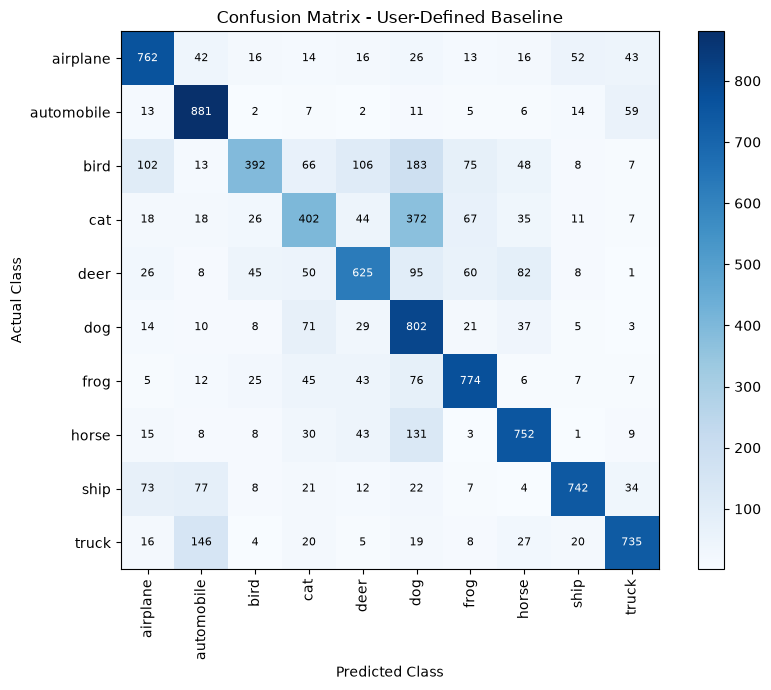

Top 5 confusions (actual -> predicted):
  cat -> dog: 372 (37.2% of all actual cat)
  bird -> dog: 183 (18.3% of all actual bird)
  truck -> automobile: 146 (14.6% of all actual truck)
  horse -> dog: 131 (13.1% of all actual horse)
  bird -> deer: 106 (10.6% of all actual bird)


In [18]:
other_model = stronger_model if best_model is baseline_model else baseline_model
other_label = "Stronger CNN" if best_model is baseline_model else "User-Defined Baseline"

y_pred_other = get_predictions(other_model)
cm_other = plot_cm(y_test, y_pred_other, f"Confusion Matrix - {other_label}")
top_confusions(cm_other, k=5)